I0000 00:00:1794307704.953304      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794307722.486539      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.21.0
GPU Available: []


E0000 00:00:1794307726.388888      50 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)



Dataset Location: /kaggle/input/datasets/dansbecker/food-101/food-101/food-101/images
Found 101000 files belonging to 101 classes.
Using 80800 files for training.
Found 101000 files belonging to 101 classes.
Using 20200 files for validation.

Total Food Categories: 101
Food Categories: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheese_plate', 'cheesecake', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic

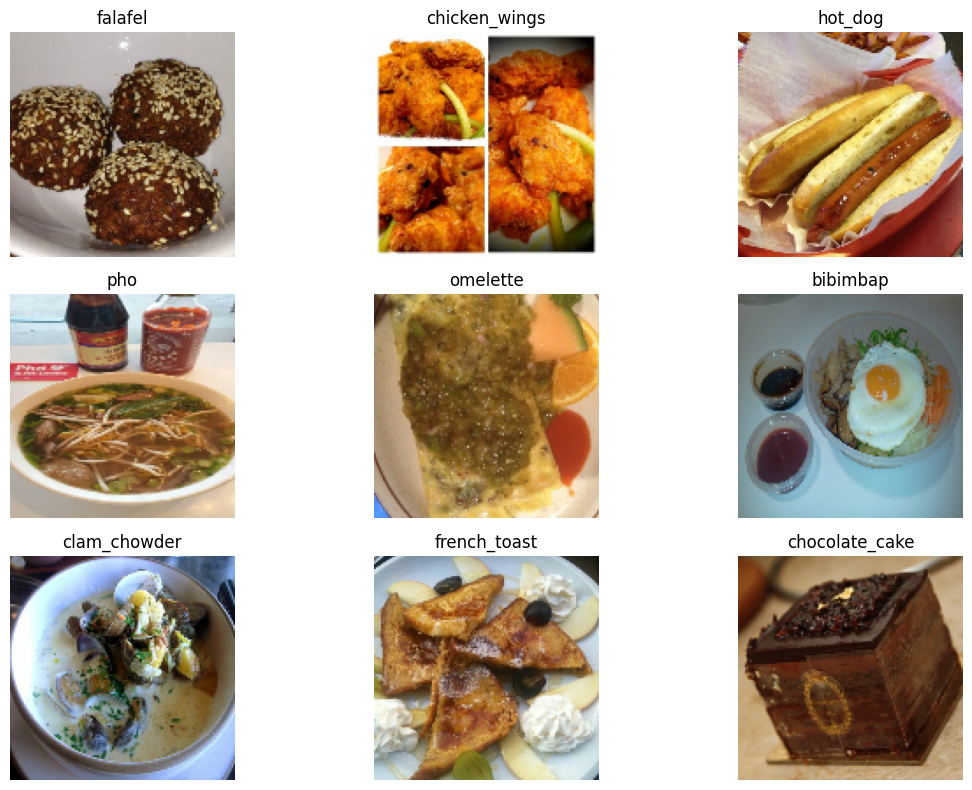

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 101)            │        25,957 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,773,925 (10.58 MB)

 Trainable params: 2,773,925 (10.58 MB)

 Non-trainable params: 0 (0.00 B)


CNN Model Compiled Successfully!

Starting CNN Model Training...
Epoch 1/10
  25/2525 ━━━━━━━━━━━━━━━━━━━━ 29:58 719ms/step - accuracy: 0.0077 - loss: 4.6326

In [ ]:

# ============================================================
# FOOD IMAGE CLASSIFICATION USING CNN
# Platform: Kaggle Notebook
# Dataset: Food-101
# Framework: TensorFlow / Keras
# ============================================================

# 1. IMPORT LIBRARIES

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))


# 2. FIND DATASET LOCATION AUTOMATICALLY

INPUT_DIR = Path("/kaggle/input/datasets/dansbecker/food-101")

image_dirs = [
    p for p in INPUT_DIR.rglob("images")
    if p.is_dir() and len([
        d for d in p.iterdir() if d.is_dir()
    ]) >= 50
]

if not image_dirs:
    raise FileNotFoundError(
        "Food-101 dataset not found. Please add it using Add Input."
    )

DATASET_PATH = image_dirs[0]

print("\nDataset Location:", DATASET_PATH)


# 3. SET PARAMETERS

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 10
SEED = 42


# 4. LOAD DATASET

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("\nTotal Food Categories:", NUM_CLASSES)
print("Food Categories:", class_names)


# 5. DISPLAY SAMPLE IMAGES

plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()


# 6. DATA AUGMENTATION

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)


# 7. BUILD CNN MODEL

model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    # CNN Layer 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # CNN Layer 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # CNN Layer 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # CNN Layer 4
    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()


# 8. COMPILE MODEL

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\nCNN Model Compiled Successfully!")


# 9. CALLBACKS

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_food_cnn.keras",
        monitor='val_accuracy',
        save_best_only=True
    )
]


# 10. TRAIN CNN MODEL

print("\nStarting CNN Model Training...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


# 11. MODEL ACCURACY AND LOSS GRAPH

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# 12. EVALUATE MODEL

loss, accuracy = model.evaluate(val_ds)

print("\n========== MODEL EVALUATION ==========")
print("Validation Loss:", loss)
print("Validation Accuracy:", round(accuracy * 100, 2), "%")


# 13. FOOD IMAGE PREDICTION FUNCTION

def predict_food(image_path):

    img = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])

    predicted_food = class_names[predicted_index]

    confidence = predictions[0][predicted_index] * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")

    plt.title(
        f"Prediction: {predicted_food}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.show()

    print("Predicted Food:", predicted_food)
    print("Confidence:", round(float(confidence), 2), "%")


# 14. TEST SAMPLE IMAGE

sample_images = list(DATASET_PATH.rglob("*.jpg"))

if sample_images:
    sample_image = str(sample_images[0])

    print("\nTesting Sample Food Image:")
    print(sample_image)

    predict_food(sample_image)


# 15. SAVE TRAINED MODEL

MODEL_PATH = "/kaggle/working/food_classification_cnn.keras"

model.save(MODEL_PATH)

# Save class names for future predictions
np.save(
    "/kaggle/working/food_class_names.npy",
    np.array(class_names)
)

print("\n========== PROJECT COMPLETED ==========")
print("Model Saved:", MODEL_PATH)
print("Class Names Saved Successfully!")
print("Total Food Categories:", NUM_CLASSES)
print("Final Validation Accuracy:", round(accuracy * 100, 2), "%")
